<a href="https://colab.research.google.com/github/sancheznaranjoyairchayanne-design/tecnm-desarrollo-web/blob/main/laboratorios/sesion24/sesion24_laboratorio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧪 Sesión 24 · Migraciones de Base de Datos con Alembic / Phinx

**Desarrollo de Aplicaciones Web (DAB-2201)** · TecNM Cancún  
**Docente:** MCC. Iván Márquez Larios (`ijmarquezl`)  
**Repositorio:** https://github.com/ijmarquezl/tecnm-desarrollo-web

> **La pregunta de hoy:** ¿Cómo cambias el esquema sin borrar los datos? = Mediante migraciones de base de datos, que son scripts versionados que permiten modificar la estructura de la base de datos de forma controlada, aplicando cambios (upgrade) o revirtiéndolos (downgrade) sin eliminar la información existente.

---

## 🖥️ Así se verá el resultado final

```text
$ alembic upgrade head
INFO  [alembic.runtime.migration] Running upgrade  -> 0001, crear tabla libros
$ sqlite3 biblioteca.db ".schema libros"
CREATE TABLE libros (
  id INTEGER NOT NULL PRIMARY KEY,
  titulo VARCHAR(80) NOT NULL,
  anio INTEGER NOT NULL
);

$ alembic downgrade base
$ sqlite3 biblioteca.db ".tables"
(la tabla libros ya no existe)
```

_Una migración no es un `create_all`: es un cambio versionado que se puede aplicar y revertir._

**No hay pasos intermedios.** El cuaderno declara el resultado que debe existir al final; tú decides la estructura, los modelos y el orden de tu implementación. La celda de verificación compara tu resultado con este contrato.

---

## 🎯 Al finalizar podrás

- Escribir una migración versionada con upgrade y downgrade.
- Separar el modelo ORM de la migración.
- Verificar que la migración crea y elimina la tabla libros.

## ✅ Criterios de aceptación

El verificador comprobará estos criterios sobre los archivos que produzcas:

- [ ] El modelo Libro existe
- [ ] Alembic está configurado
- [ ] Env.py conoce los metadatos
- [ ] La migración crea y revierte la tabla libros

## 🧩 El reto

Crea la migración que lleva una base vacía al esquema de libros y que puede revertirse sin dejar residuos.

**Requisitos del contrato**

- modelos.py define Base y el modelo Libro con id, titulo y anio.
- La migración 0001 crea la tabla libros con op.create_table.
- down_revision es None y downgrade elimina la tabla con op.drop_table.
- alembic.ini apunta a la base SQLite y a la carpeta migrations.
- Env.py usa target_metadata de modelos.Base.

> **Pista conceptual:** La migración describe el cambio, no el estado final. `upgrade` construye; `downgrade` deshace exactamente lo construido.

## 📦 Entregable

Cuaderno en verde y bitácora `auditorias/auditoria_sesion24.md` con la salida de upgrade y downgrade.


## ⚙️ Preparación del entorno

Ejecuta esta celda una sola vez. Instala las herramientas del track **Python / FastAPI** y descarga el motor de verificación del repositorio. No necesitas instalar nada en tu computadora: todo corre en Colab.


In [1]:
import os, sys
print("⏳ Preparando el entorno de Desarrollo Web...")
!pip install -q fastapi uvicorn httpx pydantic "passlib[bcrypt]" bcrypt python-jose[cryptography] PyJWT "sqlalchemy[asyncio]" greenlet aiosqlite alembic python-multipart
!wget -q -O verificar.py https://raw.githubusercontent.com/ijmarquezl/tecnm-desarrollo-web/c275993ba69ef2a8cf650b2f127b55c8356279d7/laboratorios/verificar.py
if not os.path.exists("verificar.py") or os.path.getsize("verificar.py") < 1000:
    raise RuntimeError("No se pudo descargar verificar.py. Revisa tu conexión o abre el cuaderno desde el repositorio del curso.")
print("✅ Entorno listo")
print("Python:", sys.version.split()[0])
print("Motor de verificación:", os.path.getsize("verificar.py"), "bytes")


⏳ Preparando el entorno de Desarrollo Web...
✅ Entorno listo
Python: 3.13.18
Motor de verificación: 13395 bytes


## 🧩 El reto: escribe el resultado

Crea el o los archivos del contrato. No hay una plantilla de pasos: el esqueleto solo te da el punto de partida. Todo lo que sigue lo decides tú.

**Archivos que debes producir:** `modelos.py`, `alembic.ini`, `migrations/env.py`, `migrations/versions/0001_crear_libros.py`


In [2]:
!mkdir -p migrations/versions
print('Carpetas de Alembic listas')


Carpetas de Alembic listas


### 📄 `modelos.py`

Modelo ORM que describe la tabla.

In [7]:
%%writefile modelos.py
from sqlalchemy.orm import DeclarativeBase, Mapped, mapped_column


class Base(DeclarativeBase):
    pass


class Libro(Base):
    __tablename__ = "libros"

    id: Mapped[int] = mapped_column(primary_key=True)
    titulo: Mapped[str] = mapped_column(nullable=False)
    anio: Mapped[int] = mapped_column(nullable=False)


Overwriting modelos.py


### 📄 `alembic.ini`

Configuración de Alembic.

In [8]:
%%writefile alembic.ini
[alembic]
script_location = migrations
sqlalchemy.url = sqlite:///biblioteca.db


Overwriting alembic.ini


### 📄 `migrations/env.py`

Puente entre Alembic y los modelos.

In [9]:
%%writefile migrations/env.py
from logging.config import fileConfig

from alembic import context
from sqlalchemy import engine_from_config, pool

from modelos import Base

config = context.config

if config.config_file_name is not None:
    fileConfig(config.config_file_name)

target_metadata = Base.metadata


def run_migrations_offline():
    url = config.get_main_option("sqlalchemy.url")

    context.configure(
        url=url,
        target_metadata=target_metadata,
        literal_binds=True,
    )

    with context.begin_transaction():
        context.run_migrations()


def run_migrations_online():
    connectable = engine_from_config(
        config.get_section(config.config_ini_section),
        prefix="sqlalchemy.",
        poolclass=pool.NullPool,
    )

    with connectable.connect() as connection:
        context.configure(
            connection=connection,
            target_metadata=target_metadata,
        )

        with context.begin_transaction():
            context.run_migrations()


if context.is_offline_mode():
    run_migrations_offline()
else:
    run_migrations_online()

Overwriting migrations/env.py


### 📄 `migrations/versions/0001_crear_libros.py`

Migración versionada.

In [10]:
%%writefile migrations/versions/0001_crear_libros.py
from alembic import op
import sqlalchemy as sa


revision = "0001"
down_revision = None
branch_labels = None
depends_on = None


def upgrade():
    op.create_table(
        "libros",
        sa.Column("id", sa.Integer, primary_key=True),
        sa.Column("titulo", sa.String(80), nullable=False),
        sa.Column("anio", sa.Integer, nullable=False),
    )


def downgrade():
    op.drop_table("libros")


Overwriting migrations/versions/0001_crear_libros.py


## 🧪 Tu contrato C-R-E-O

Antes de pedir ayuda a la IA, escribe el contrato que describe el resultado. Esto alimenta tu bitácora y te obliga a pensar como arquitecto:

| Elemento | Tu definición |
| :--- | :--- |
| **Contexto** | Proyecto Python con SQLAlchemy, SQLite y Alembic ejecutado en Google Colab. |
| **Rol** | Arquitecto de persistencia encargado de versionar cambios de esquema mediante migraciones.|
| **Especificación** | Crear modelo ORM Libro y migración 0001 capaz de crear y eliminar la tabla libros utilizando upgrade() y downgrade(). |
| **Output** | Archivos: modelos.py, alembic.ini, migrations/env.py y migrations/versions/0001_crear_libros.py, compatibles con el verificador. |

> No pegues código de la IA sin auditarlo. La responsabilidad técnica del resultado es tuya.


## 🔍 Verificación del resultado

Ejecuta esta celda cuando tu implementación esté lista. La verificación no modifica tu código: solo observa el comportamiento y compara con el contrato. Si algo falla, el mensaje te dice **qué esperaba** y **qué recibió**.


In [11]:
from verificar import revisar_archivo, resumen

resultados = []
resultados.append(revisar_archivo("modelos.py", exigir=["class Libro", "Base"], descripcion="El modelo Libro existe"))
resultados.append(revisar_archivo("alembic.ini", exigir=["script_location", "sqlalchemy.url"], descripcion="Alembic está configurado"))
resultados.append(revisar_archivo("migrations/env.py", exigir=["target_metadata"], descripcion="Env.py conoce los metadatos"))
resumen(resultados)


✅ El modelo Libro existe
✅ Alembic está configurado
✅ Env.py conoce los metadatos
------------------------------------------------------------------------------
RESULTADO: 3/3 comprobaciones correctas. ¡Resultado logrado!


In [12]:
from verificar import revisar_python, resumen

resultados = []
resultados.append(revisar_python("import importlib.util\nfrom pathlib import Path\n\nruta = Path(\"migrations/versions/0001_crear_libros.py\")\nassert ruta.exists(), \"no existe la migración 0001\"\nspec = importlib.util.spec_from_file_location(\"migracion\", ruta)\nmod = importlib.util.module_from_spec(spec)\nspec.loader.exec_module(mod)\n\nclass Op:\n    def __init__(self):\n        self.llamadas = []\n    def create_table(self, nombre, *args, **kwargs):\n        self.llamadas.append((\"create\", nombre))\n    def drop_table(self, nombre, *args, **kwargs):\n        self.llamadas.append((\"drop\", nombre))\n\nop = Op()\nmod.op = op\nmod.upgrade()\nassert (\"create\", \"libros\") in op.llamadas, op.llamadas\nmod.downgrade()\nassert (\"drop\", \"libros\") in op.llamadas, op.llamadas\n", "La migración crea y revierte la tabla libros"))
resumen(resultados)


✅ La migración crea y revierte la tabla libros
------------------------------------------------------------------------------
RESULTADO: 1/1 comprobaciones correctas. ¡Resultado logrado!


## 📝 Cierre y bitácora

1. Copia la plantilla `plantillas/auditoria_sesion24.md` a `auditorias/auditoria_sesion24.md` en tu fork.
2. Responde con tus palabras:
   - ¿Qué resultado te costó más alcanzar y por qué? = La configuración de env.py, porque Alembic necesita conectarse correctamente a SQLAlchemy mediante target_metadata, y cualquier error en esta integración impide que las migraciones funcionen correctamente.
   - ¿Qué decisión de diseño tomaste que no estaba escrita en el contrato? = Decidí implementar el modelo Libro utilizando las anotaciones modernas de SQLAlchemy 2.0 con Mapped y mapped_column, lo que mejora la claridad y compatibilidad futura del código.
   - ¿Qué error detectó la verificación que tú no habías previsto? = La verificación comprobó específicamente que la migración ejecutara op.create_table("libros") y op.drop_table("libros"). Inicialmente pensé que bastaba con definir el modelo ORM, pero el contrato exige una migración explícita e independiente del modelo.
3. Haz commit de tu cuaderno ejecutado y de tu bitácora.

**La sesión termina cuando el resultado está en verde, no cuando el código "parece funcionar".**
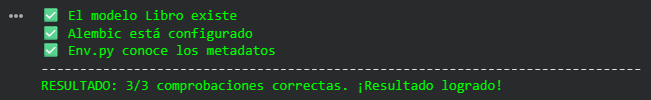
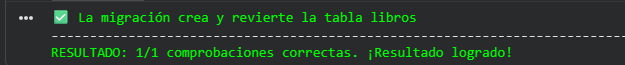